<a href="https://colab.research.google.com/github/eeeewyz/TTS-experients/blob/main/1_flowmatching_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

我们有两个分布
初始分布 z（Gaussian Noise）：
我们生成 1000 个二维随机点，它们主要集中在 (0, 0) 附近。

目标分布 x1（Target Data）：

我们提前生成了另外 1000 个点：
- 500 个点集中在 (2, 2) 附近。
- 500 个点集中在 (-2, -2) 附近。
我们希望模型学会把第一种分布变成第二种分布。
2. MLP 到底学到了什么？
假设目前有一个随机点：

z = [0.5, 0.3]

我们希望这个点经过多次移动，最终进入目标分布的某个区域。

MLP 学习的不是这个点应该到达哪个固定目标点，而是：

如果一个点现在位于 (x, y)，并且当前时间为 t，那么它应该往哪个方向、以多快的速度移动？
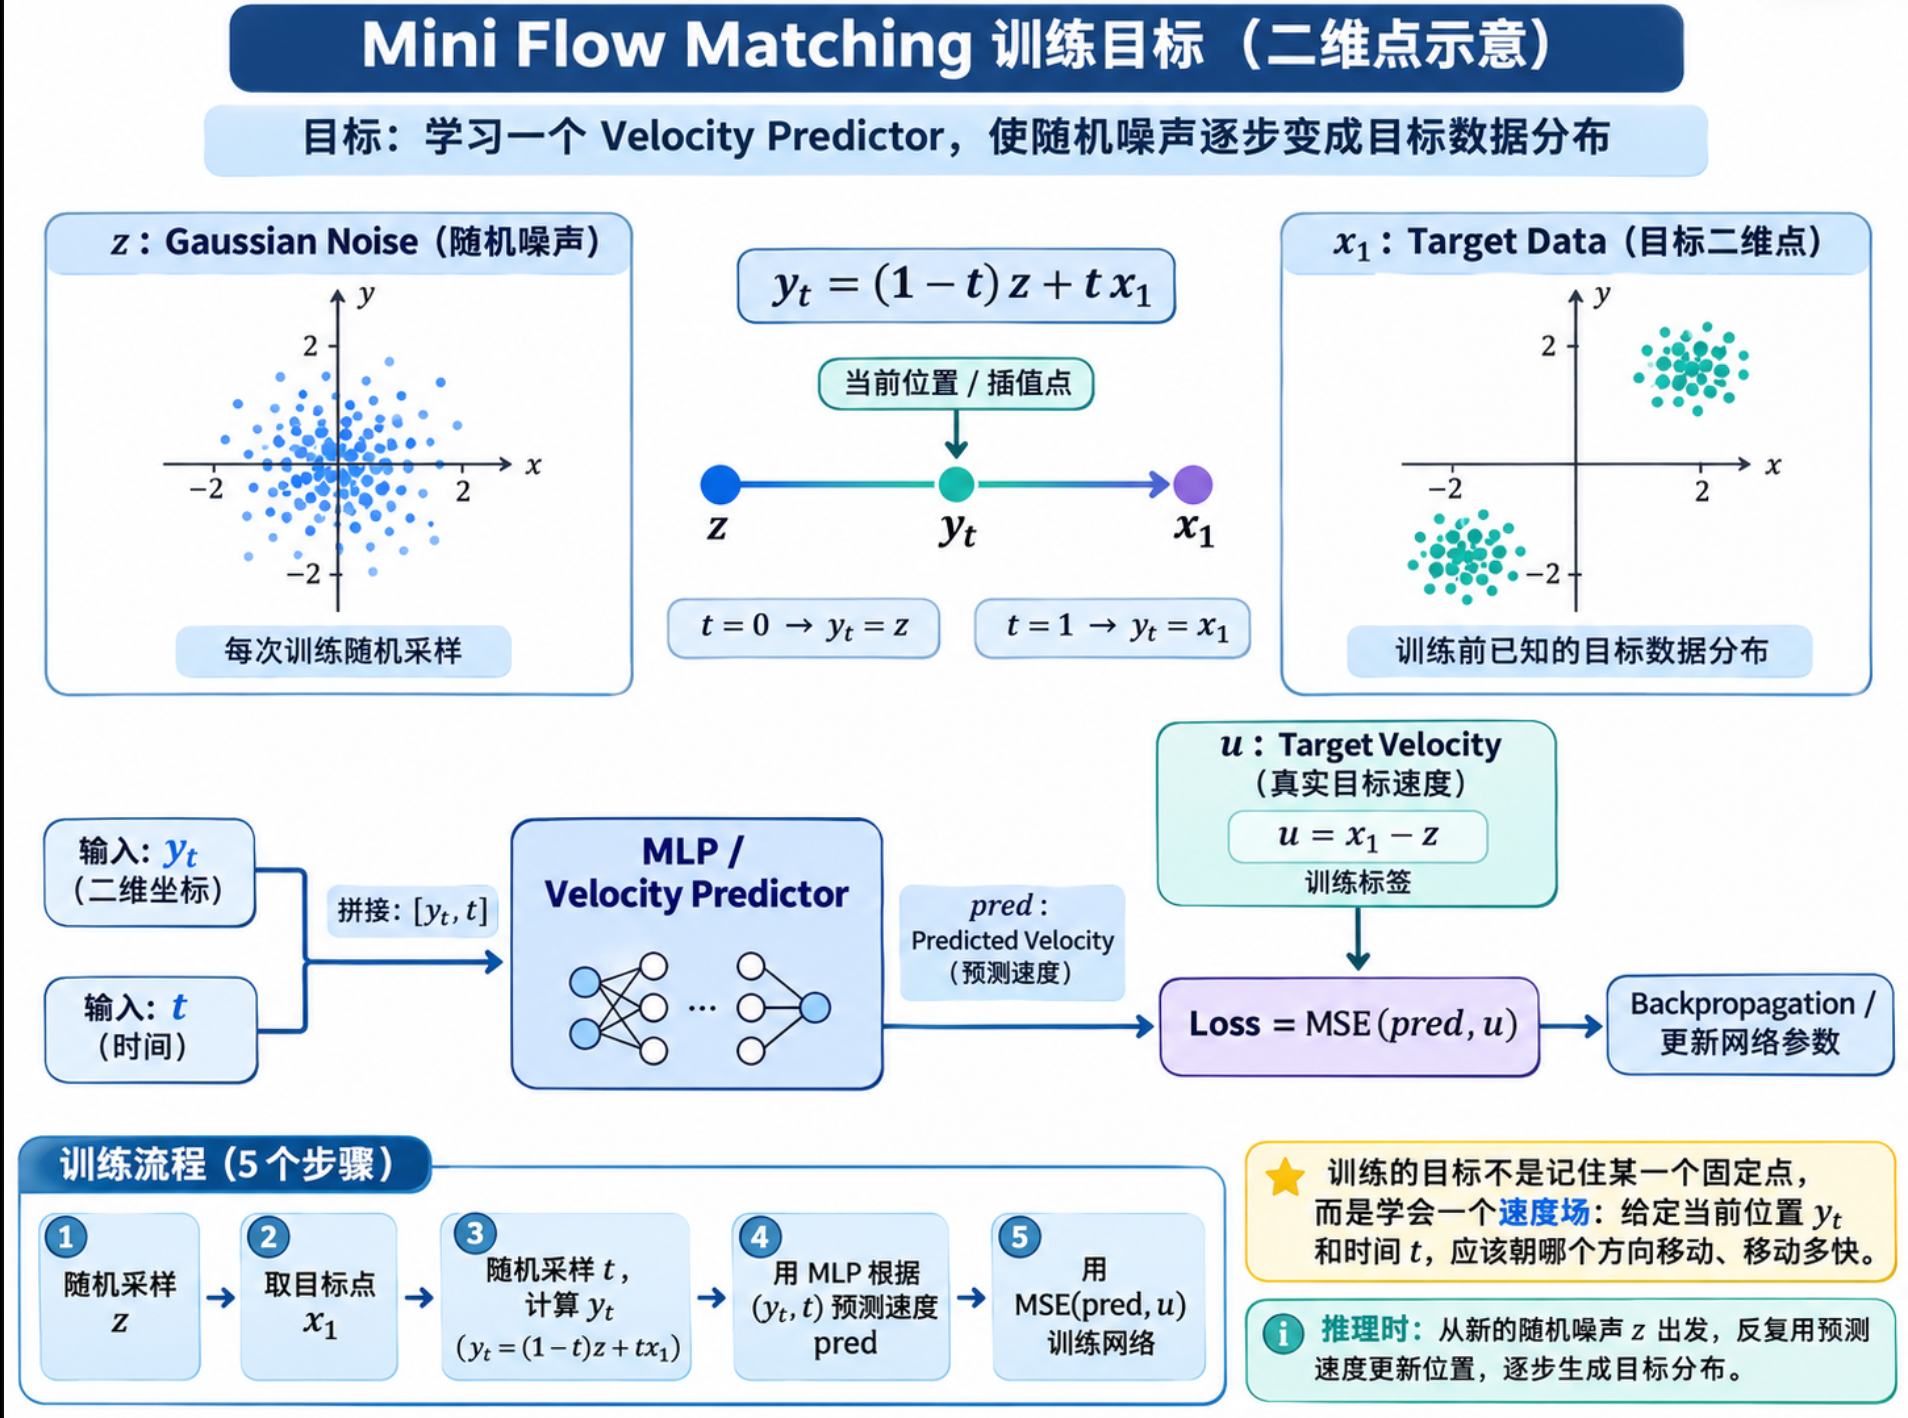







总结：Training： 学习在不同位置和时间下应该预测什么 Velocity。

Inference： 从 Gaussian Noise 出发，反复利用预测的 Velocity 更新坐标，最终生成目标分布。

In [ ]:
import torch
import torch.nn.functional as F

# 固定随机种子，保证实验结果可以复现
torch.manual_seed(42)

# 自动选择 GPU 或 CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)


PyTorch version: 2.11.0+cpu
Device: cpu


In [ ]:
import torch
#torch.nn 是 PyTorch 中的 Neural Network模块，主要用于构建和训练神经网络。
import torch.nn.functional as F

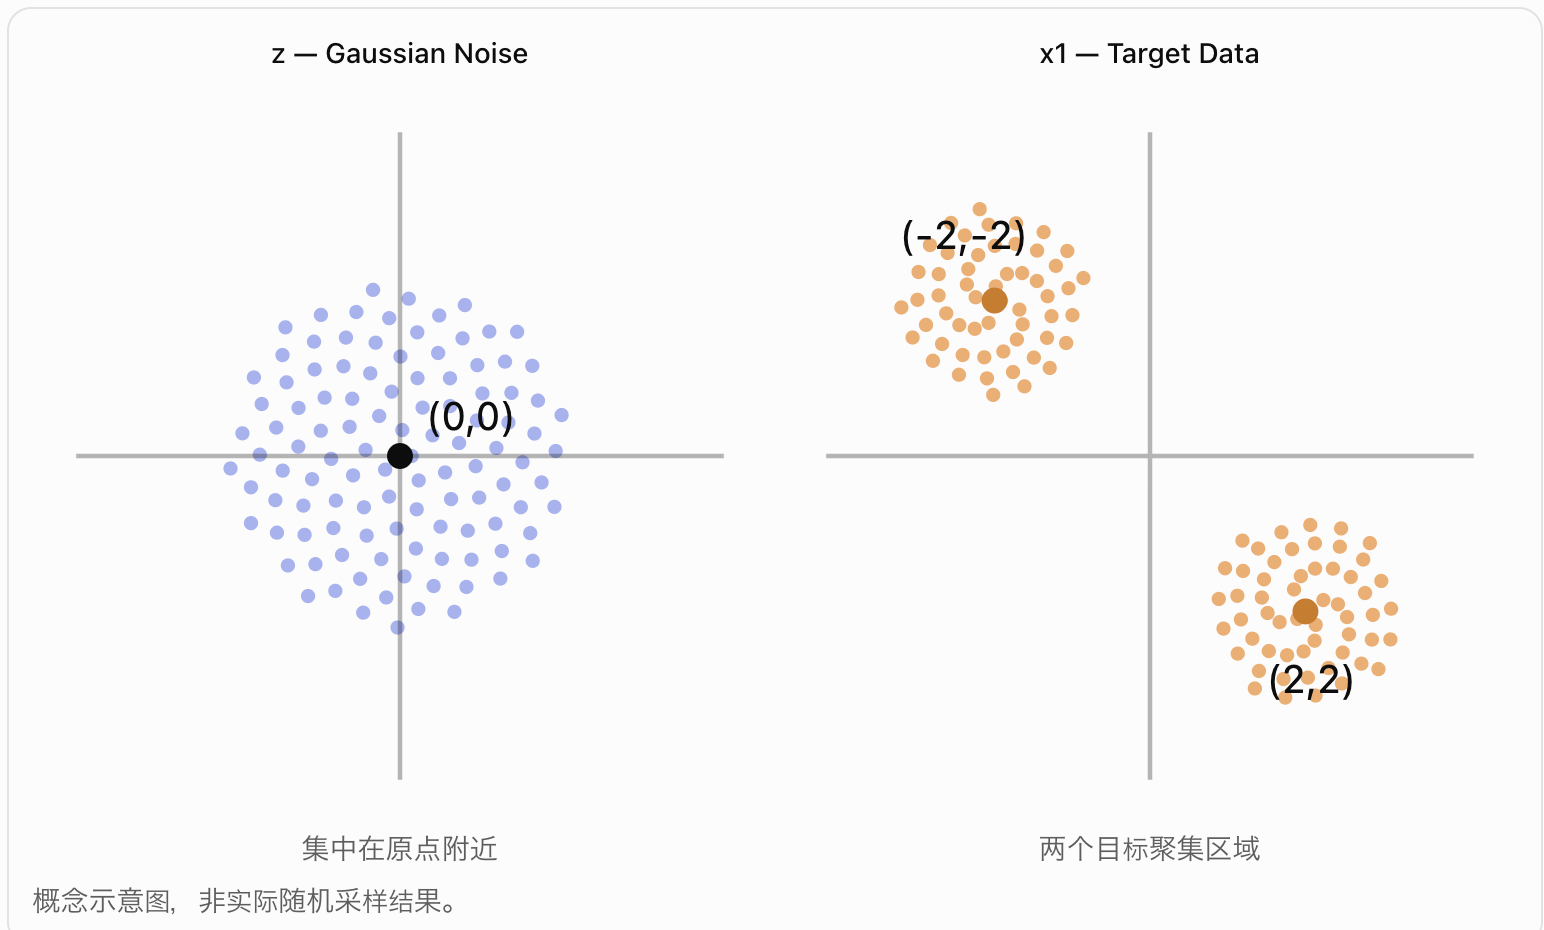

In [ ]:
# 在原版 CosyVoice 3 中，x1 是真实 Mel Spectrogram，形状通常为 (B, 80, T)。
# 这里简化为二维点 (1000, 2)，便于后续观察 Flow Matching 如何将 Noise 转换为目标数据分布。


In [ ]:
#x1：目标数据（Target Data），也就是希望模型最终生成的数据。
# z：随机噪声（Gaussian Noise），也就是模型生成数据的起点。

# Step 2: 创建 Target Data 和 Gaussian Noise

# 第一组：生成500个二维点
# 500 = 样本数量（Number of Samples）
# 2 = 每个样本的维度（X、Y两个坐标）
# torch.randn：从标准正态分布 N(0,1) 随机采样
# 加 [2.0, 2.0]：让这些点集中在 (2,2) 附近
group1 = torch.randn(500, 2) + torch.tensor([2.0, 2.0])

# 第二组：生成另外500个二维点
# 让这些点集中在 (-2,-2) 附近
group2 = torch.randn(500, 2) + torch.tensor([-2.0, -2.0])

# 合并两组数据，作为目标数据 x1
# dim=0：沿第0维（样本数量维度）拼接
# 最终 Shape：(1000, 2)
# .to(device)：将数据移动到 CPU 或 GPU
x1 = torch.cat([group1, group2], dim=0).to(device)

# 创建 Gaussian Noise（随机噪声）
# randn_like(x1)：生成与 x1 相同 Shape 的随机 Tensor
# Shape：(1000, 2)，数值来自 N(0,1)
z = torch.randn_like(x1)

# 查看结果
print("group1:", group1.shape)
print("group2:", group2.shape)
print("x1:", x1.shape)
print("z:", z.shape)

print("x1 第一个样本:", x1[0])
print("z 第一个样本:", z[0])





group1: torch.Size([500, 2])
group2: torch.Size([500, 2])
x1: torch.Size([1000, 2])
z: torch.Size([1000, 2])
x1 第一个样本: tensor([3.9269, 3.4873])
z 第一个样本: tensor([-0.6960,  0.5155])


In [ ]:
# b = 决定生成多少个随机时间值。
# t 决定每个训练样本在 Noise → Target 这条路径上的位置。
# 因为 Flow Matching 要让模型学习整个生成过程，而不只是起点或终点。比如：
# t = [
#     [0.2],  # 第1个样本
#     [0.7],  # 第2个样本
#     [0.5],  # 第3个样本
#     ...
# ]

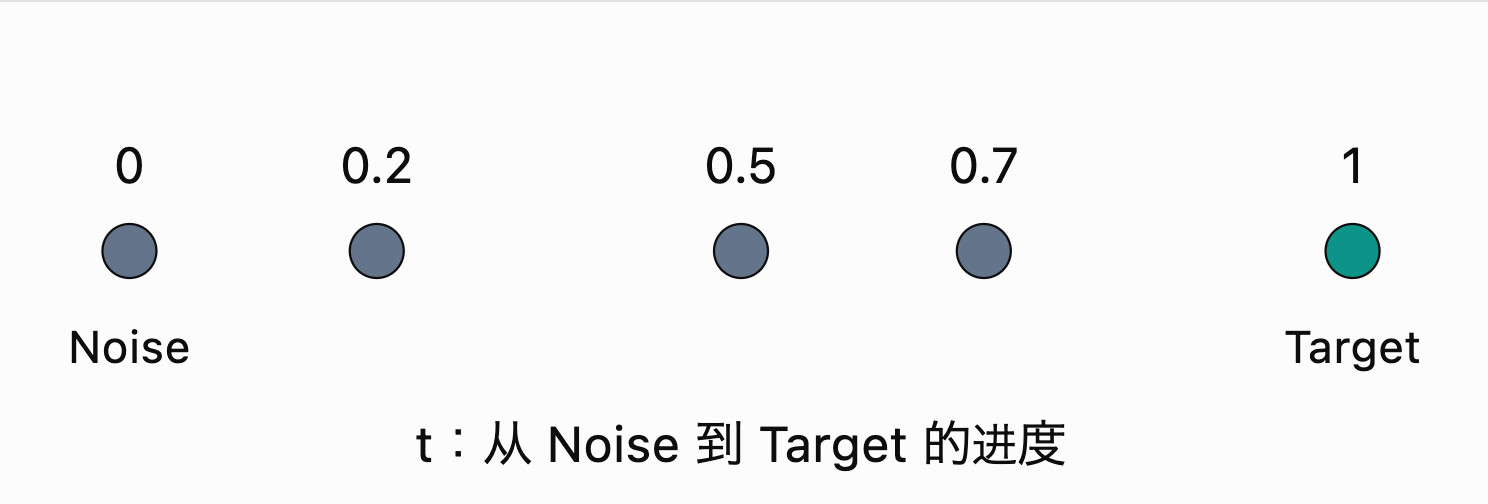

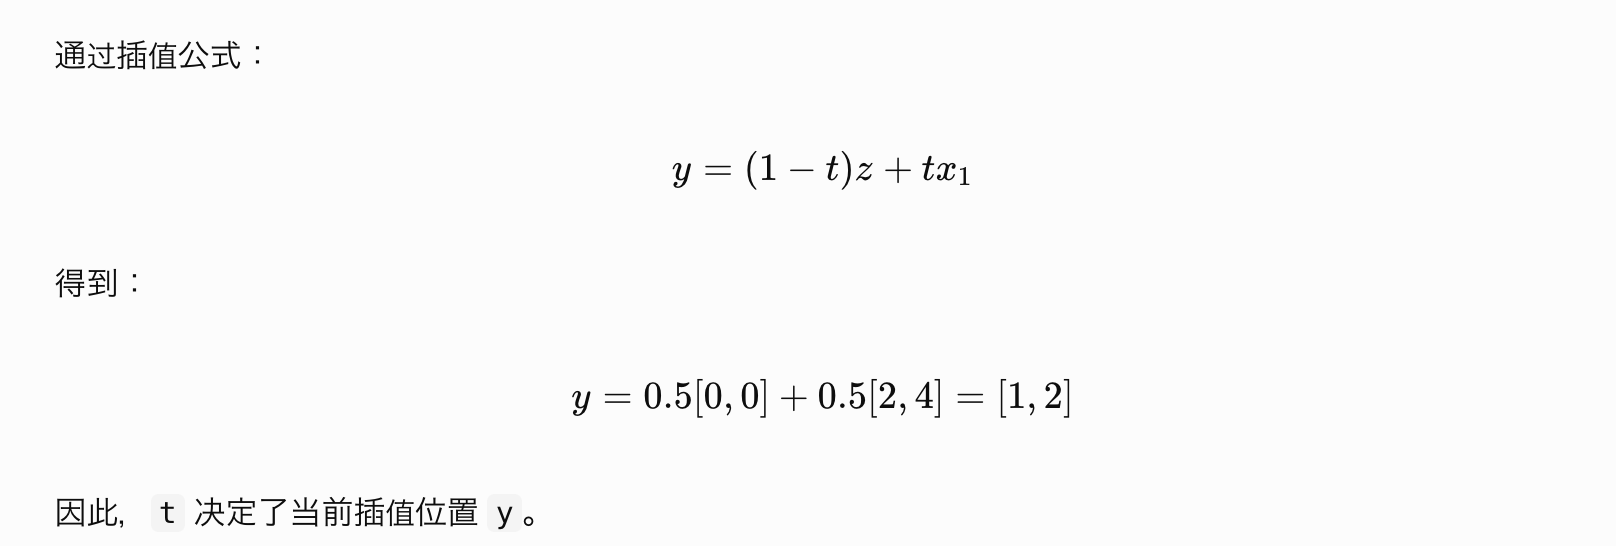

In [ ]:
# # 1. sigma_min 是什么？
# # sigma_min 是最小噪声系数（Minimum Noise Scale）。
# # 它控制 Flow Matching 到达终点 t=1 时，还保留多少 Gaussian Noise。
# 它的主要作用是让训练路径的终点保留非零噪声，避免完全退化为零方差分布，符合 CFM 中常用的数值稳定性设计。

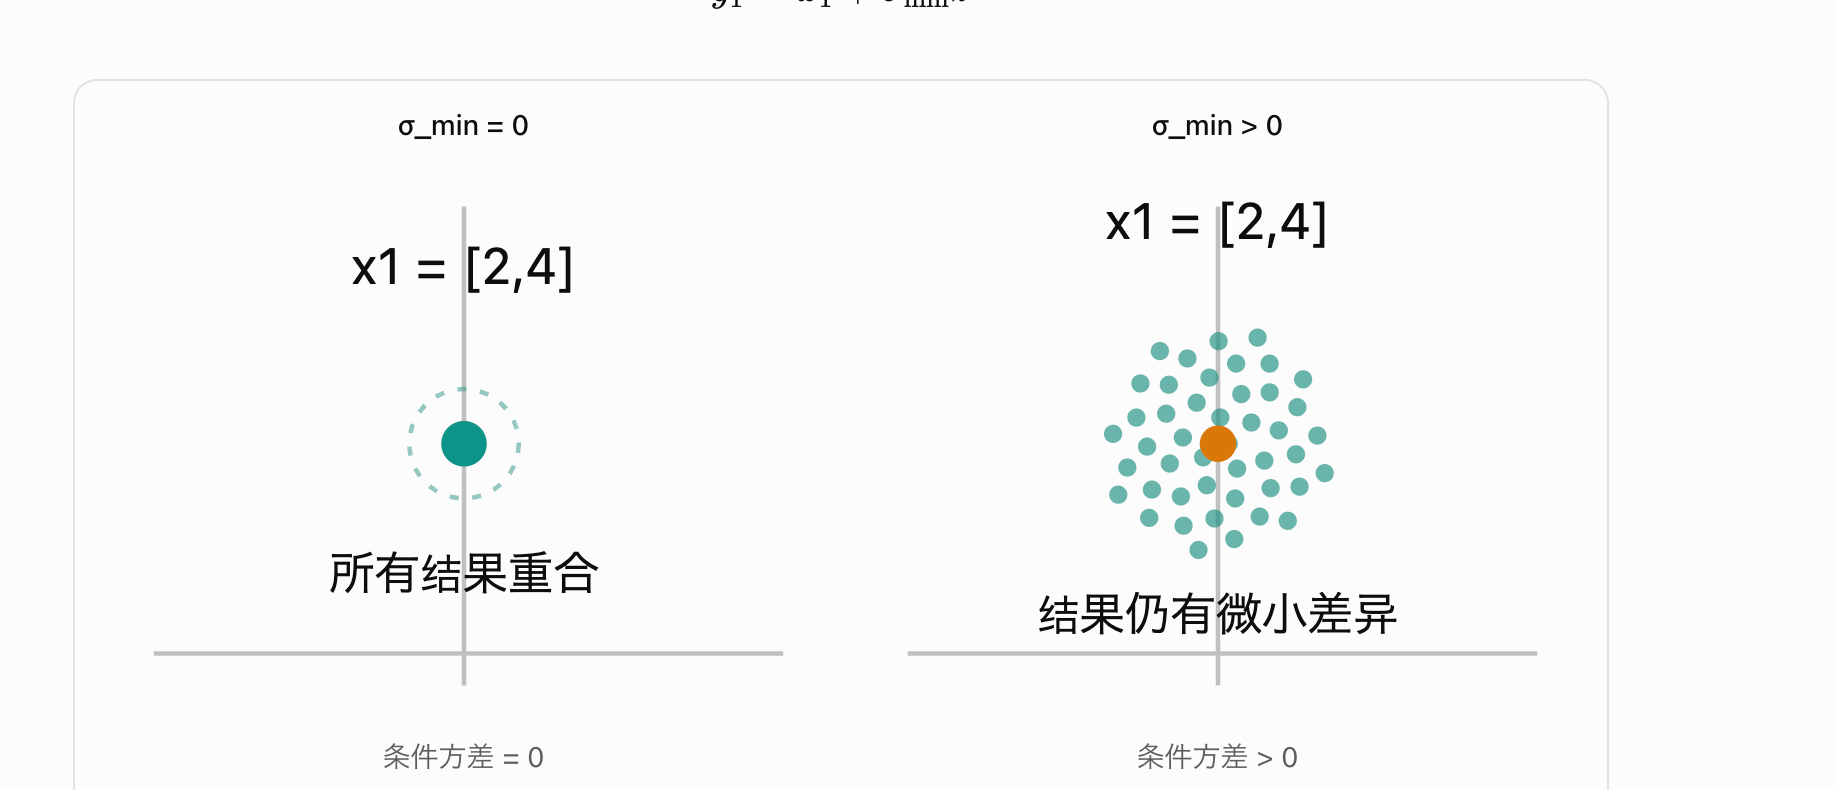

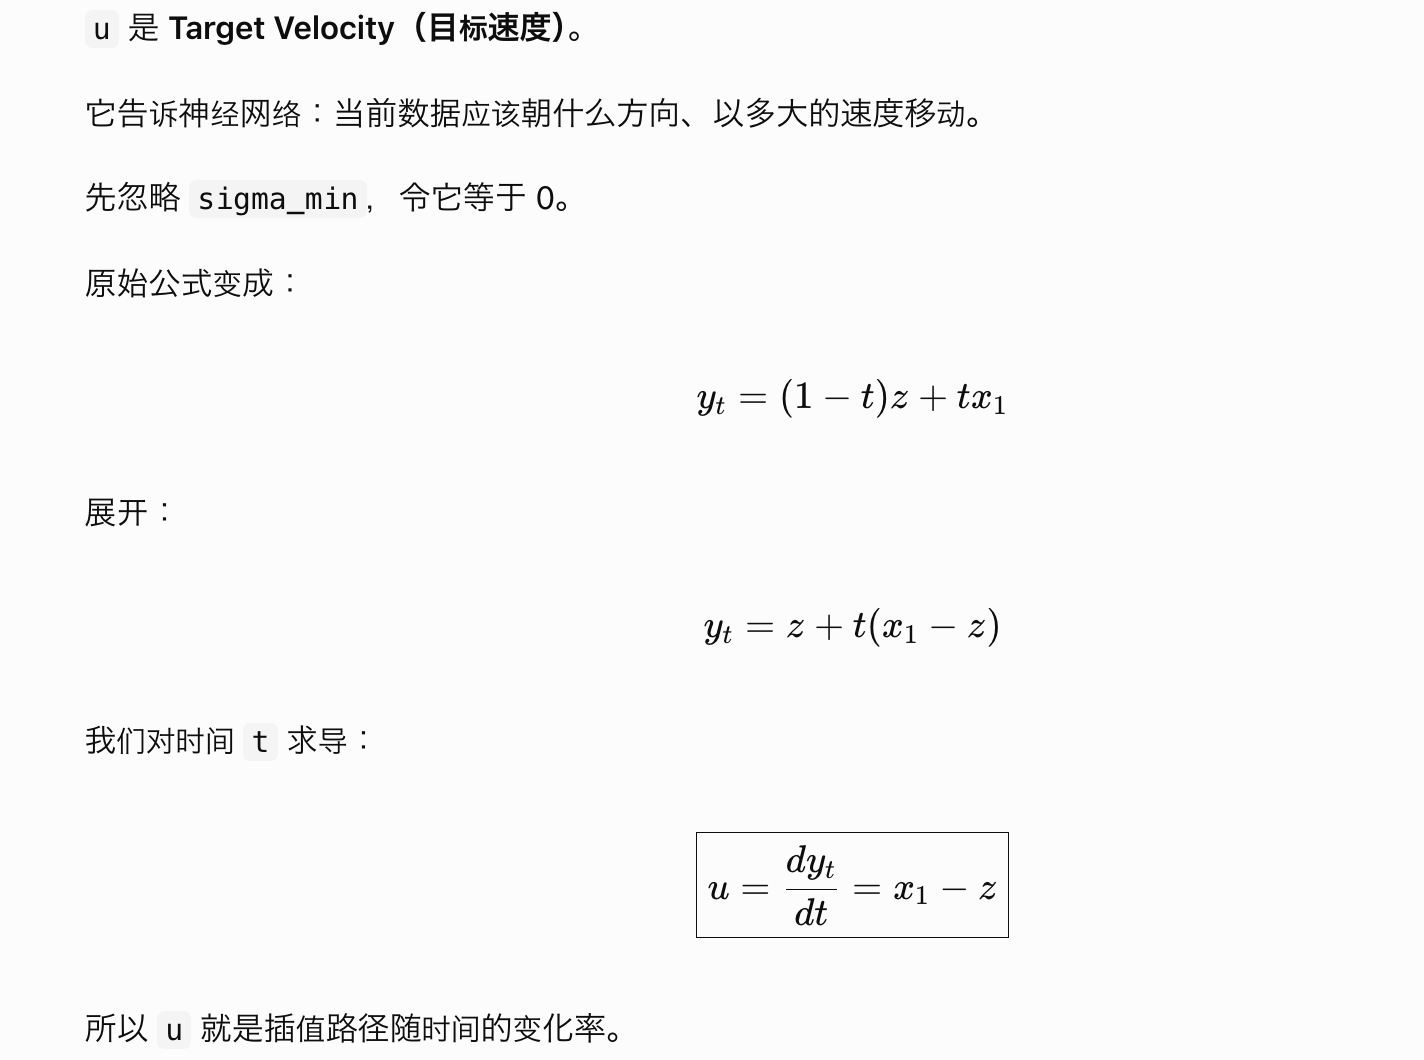

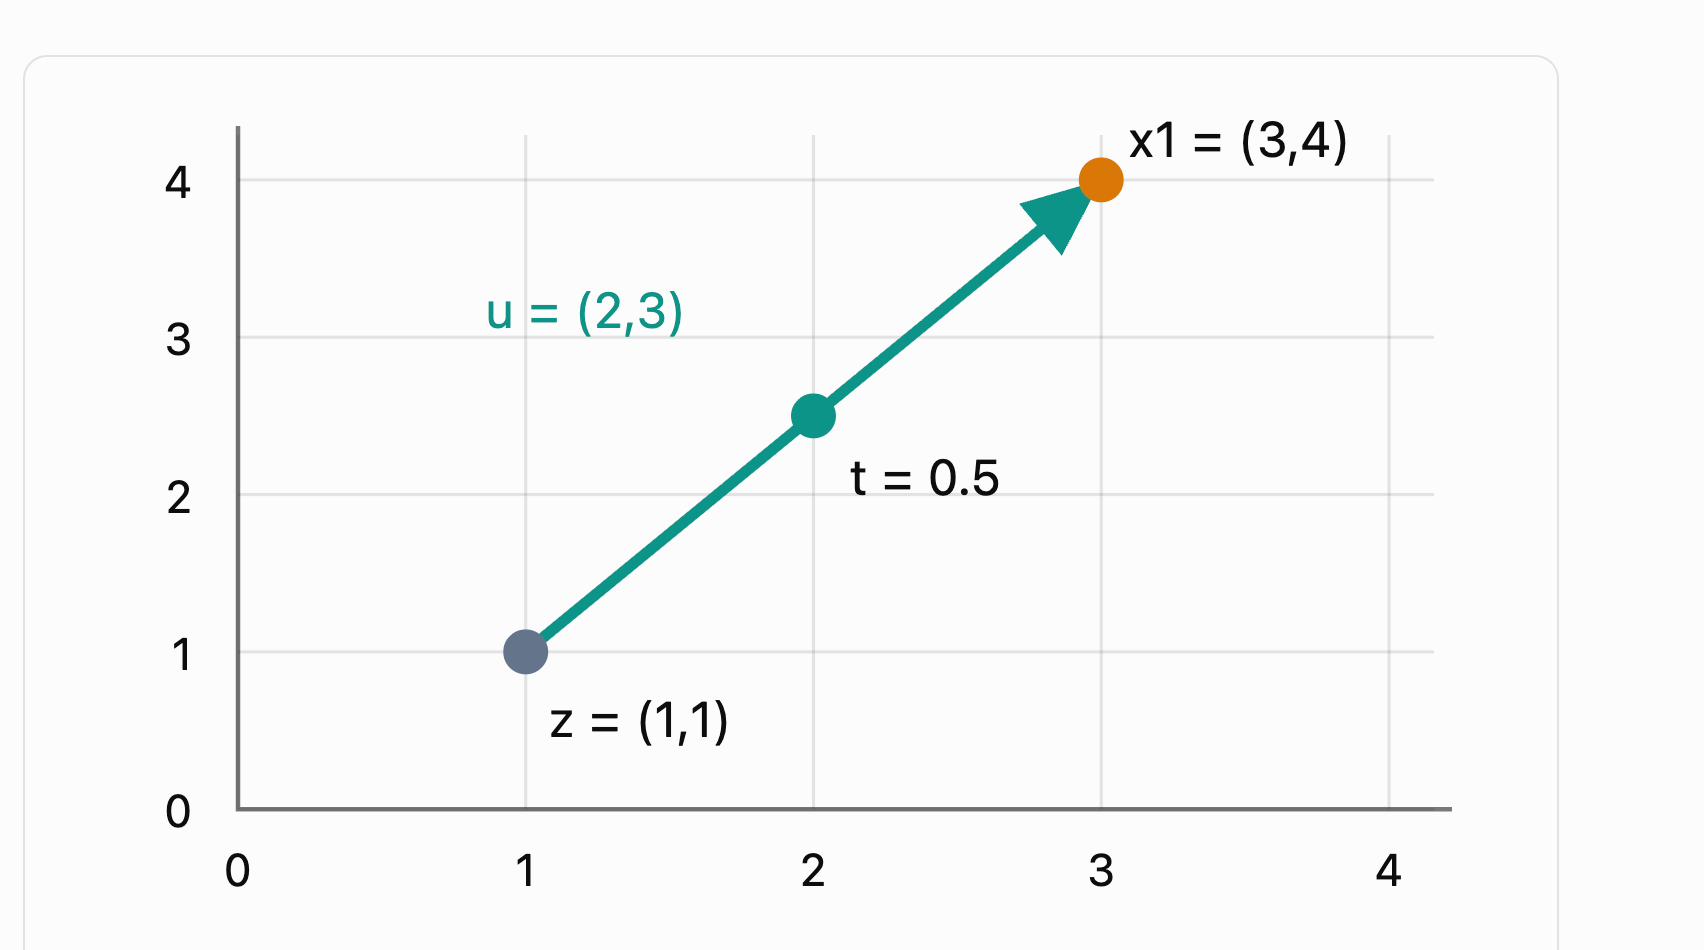

In [ ]:
# Step 3: 计算 Flow Matching 的插值位置和目标速度
# 获取 Batch Size（样本数量）
# x1.shape = (1000, 2)，所以 b = 1000
b = x1.shape[0]

# 为每个样本随机生成一个时间 t
# torch.rand：从 Uniform Distribution U(0,1) 采样
# Shape：(1000, 1)，每个样本对应一个随机时间
t = torch.rand(b, 1, device=device)

# 设置最小噪声系数
# 原版 CosyVoice 3 从 self.sigma_min 读取该参数
# 这里设为 0，方便理解最基本的 Flow Matching
sigma_min = 0.0

# 计算插值位置 y
# t=0 时：y=z（完全是 Noise）
# t=1 时：y=x1（完全是 Target Data）
# 0<t<1 时：y 位于 z 和 x1 之间
y = (1 - (1 - sigma_min) * t) * z + t * x1

# 计算 Target Velocity（目标速度），即对前面y求导
# 表示从 Noise 向 Target Data 移动的方向与速度
# sigma_min=0 时：u=x1-z
u = x1 - (1 - sigma_min) * z

# 查看 Tensor Shape
print("t shape:", t.shape)
print("y shape:", y.shape)
print("u shape:", u.shape)

# 查看第一个样本的数值
print("t[0]:", t[0])
print("y[0]:", y[0])
print("u[0]:", u[0])


t shape: torch.Size([1000, 1])
y shape: torch.Size([1000, 2])
u shape: torch.Size([1000, 2])
t[0]: tensor([0.8937])
y[0]: tensor([3.4356, 3.1714])
u[0]: tensor([4.6229, 2.9718])


In [ ]:
#  MLP、U-Net、DiT 是负责预测 Velocity 的神经网络。
# 这里我们用mlp定义一个简单的网络来实验，后面再换Dit

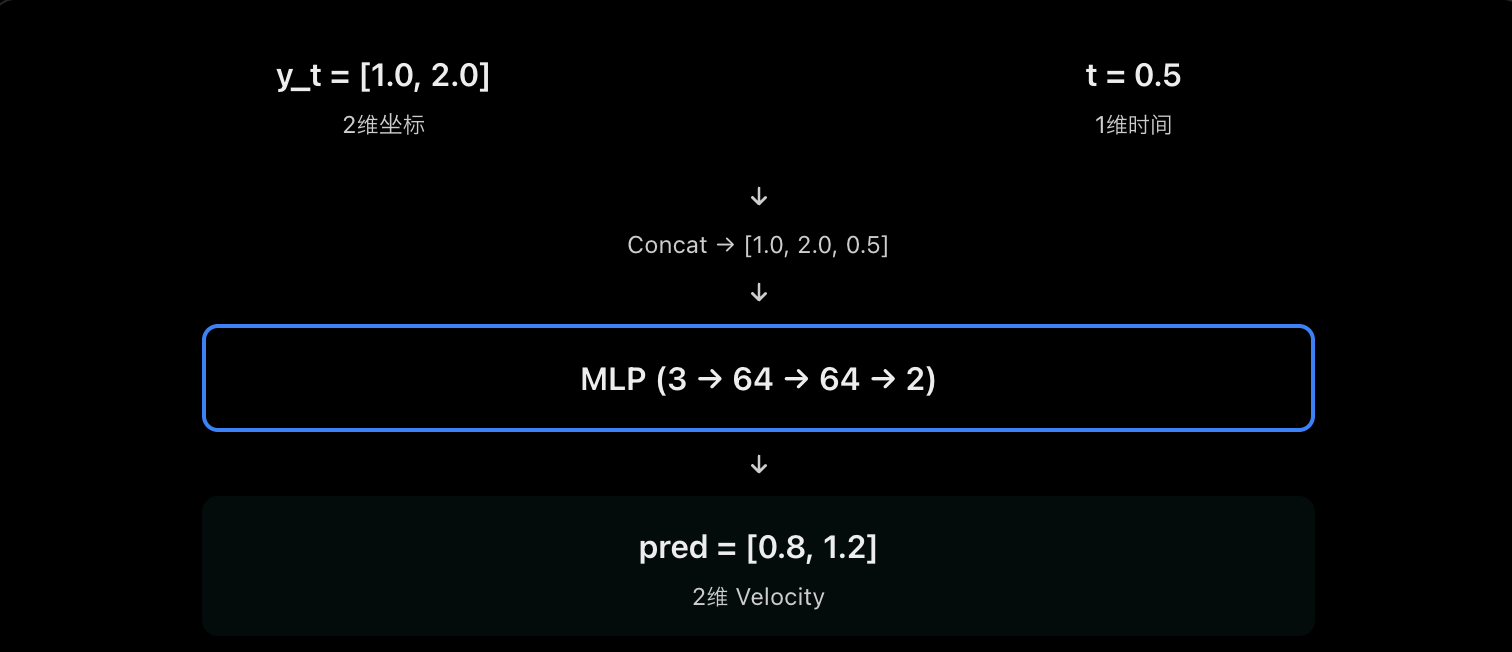

In [ ]:
# Step 4：创建 Velocity Predictor（MLP）

import torch.nn as nn
# 定义 Velocity Predictor 神经网络
# nn.Module：PyTorch 神经网络的基类
class VelocityPredictor(nn.Module):

    def __init__(self):
        super().__init__()

        # 定义 MLP 网络结构
        # 输入：y（2维）+ t（1维）= 3维
        # 输出：Predicted Velocity（2维）
        self.net = nn.Sequential(
            nn.Linear(3, 64),    # 第一层：3维 → 64维
            nn.ReLU(),           # 激活函数：增加非线性表达能力
            nn.Linear(64, 64),   # 第二层：64维 → 64维
            nn.ReLU(),           # 激活函数
            nn.Linear(64, 2)     # 输出层：64维 → 2维
        )

    # Forward：定义神经网络的前向传播
    def forward(self, y, t):

        # y Shape：(1000, 2)
        # t Shape：(1000, 1)

        # 将 y 和 t 沿特征维度拼接
        # (1000, 2) + (1000, 1) → (1000, 3)
        x = torch.cat([y, t], dim=1)

        # 使用 MLP 预测 Velocity
        # 输出 Shape：(1000, 2)
        pred = self.net(x)

        return pred


# 创建 Estimator，并移动到 CPU 或 GPU
estimator = VelocityPredictor().to(device)

# 测试 Forward（当前还没有训练）
pred = estimator(y, t)

# 查看输入输出 Shape
print("y shape:", y.shape)
print("t shape:", t.shape)
print("pred shape:", pred.shape)
print("u shape:", u.shape)

# 查看第一个样本的预测速度和目标速度
print("Predicted Velocity:", pred[0])
print("Target Velocity:", u[0])


y shape: torch.Size([1000, 2])
t shape: torch.Size([1000, 1])
pred shape: torch.Size([1000, 2])
u shape: torch.Size([1000, 2])
Predicted Velocity: tensor([-0.0894,  0.2263], grad_fn=<SelectBackward0>)
Target Velocity: tensor([4.6229, 2.9718])


In [ ]:
# 现在我们已经创建了 VelocityPredictor，下一步就是让它学会预测 Velocity。
# 核心过
# (y, t) → MLP → pred → MSE(pred, u) → Backpropagation

Z、T、Y、U 的关系
- z：随机生成的 Gaussian Noise。
- t：随机采样的时间，范围为 0～1。
- x1：目标数据，我们预先生成的二维点。
- y：不是独立随机生成的，而是根据 z、t、x1 计算得到的。
- u：Target Velocity，相当于训练时的 Ground Truth Label，也是通过公式计算出来的。

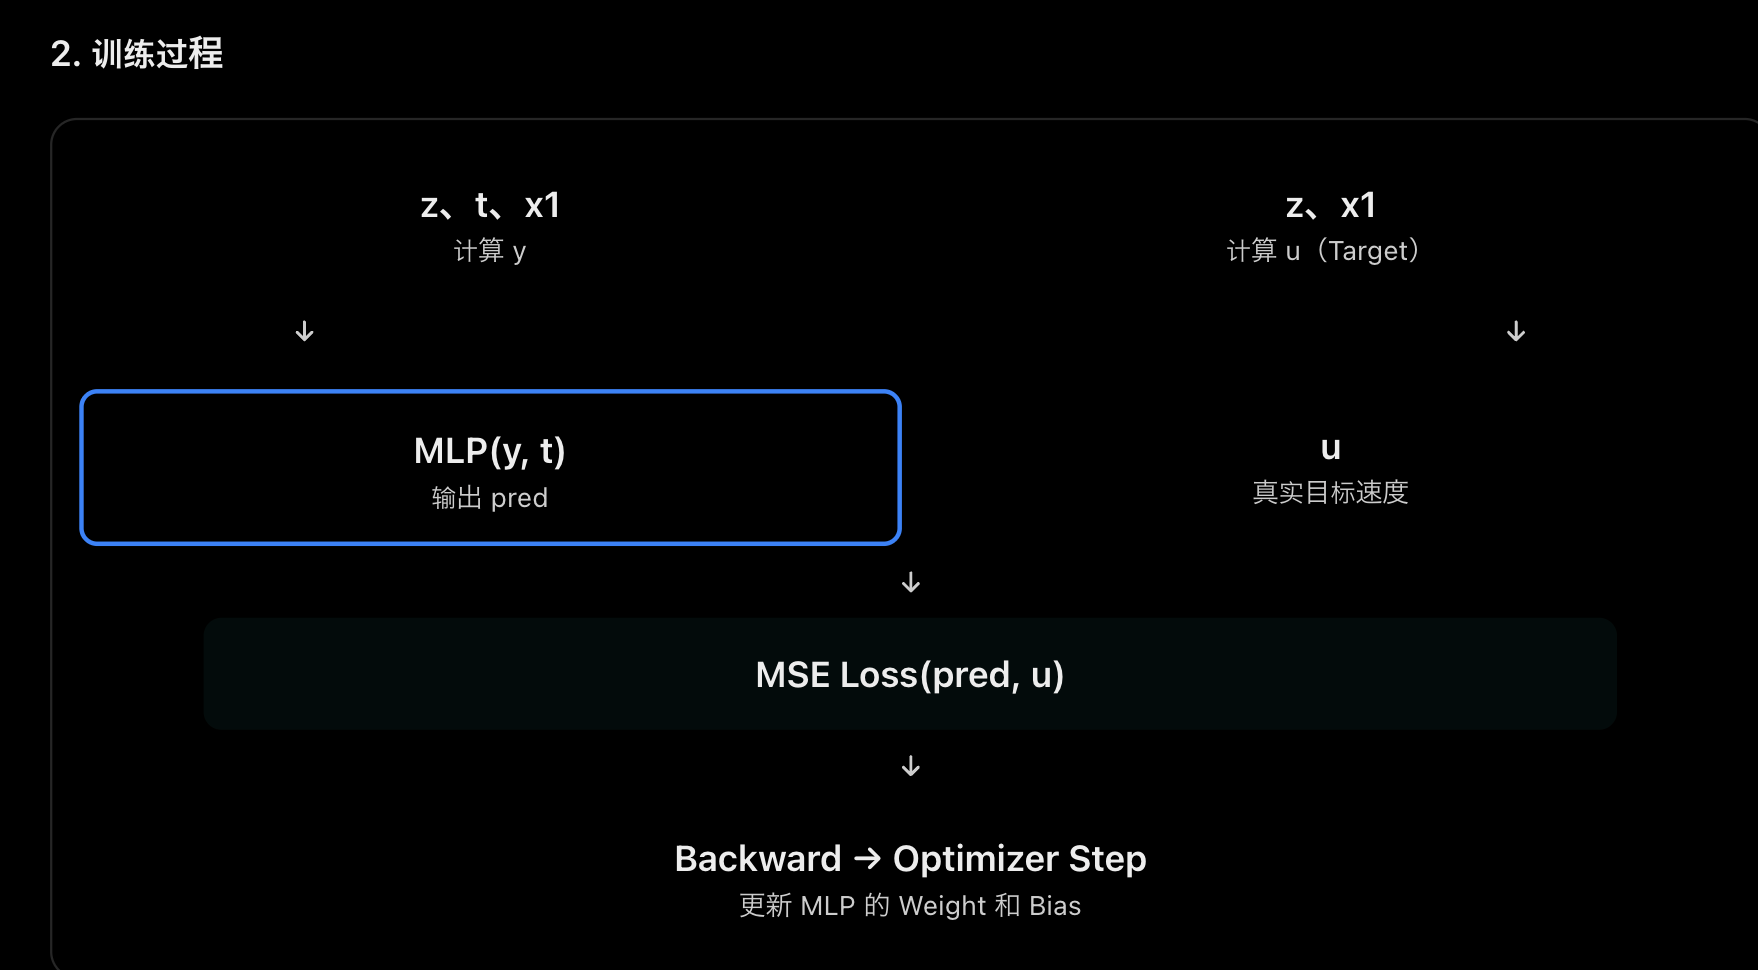



In [ ]:
# Step 5：训练 Velocity Predictor（MLP）

# 创建 Optimizer（优化器）
# Adam：通过梯度更新 MLP 的参数
# lr=0.001：Learning Rate（学习率）
optimizer = torch.optim.Adam(estimator.parameters(), lr=0.001)

# 设置训练次数
num_epochs = 2000

# 保存 Loss，后面用于绘制训练曲线
loss_history = []

# 开始训练
for epoch in range(num_epochs):

    # 每次训练重新生成 Gaussian Noise
    # Shape：(1000, 2)
    z = torch.randn_like(x1)

    # 每个样本重新生成随机时间 t
    # Shape：(1000, 1)
    t = torch.rand(x1.shape[0], 1, device=device)

    # 计算插值位置 y
    # 对应 CosyVoice 3 原版 compute_loss()
    y = (1 - (1 - sigma_min) * t) * z + t * x1

    # 计算 Target Velocity（真实目标速度）
    u = x1 - (1 - sigma_min) * z

    # MLP 根据当前位置 y 和时间 t 预测 Velocity
    pred = estimator(y, t)

    # 计算 Flow Matching Loss
    # 比较预测速度 pred 与真实目标速度 u
    loss = F.mse_loss(pred, u)

    # 清除上一轮的梯度
    optimizer.zero_grad()

    # Backpropagation：计算参数梯度
    loss.backward()

    # 更新 MLP 参数
    optimizer.step()

    # 保存当前 Loss
    loss_history.append(loss.item())

    # 每200轮输出一次训练结果
    if (epoch + 1) % 200 == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {loss.item():.4f}")


Epoch 200/2000, Loss: 3.3462
Epoch 400/2000, Loss: 3.2202
Epoch 600/2000, Loss: 2.7217
Epoch 800/2000, Loss: 2.8616
Epoch 1000/2000, Loss: 2.9645
Epoch 1200/2000, Loss: 2.9864
Epoch 1400/2000, Loss: 2.9461
Epoch 1600/2000, Loss: 3.0233
Epoch 1800/2000, Loss: 3.0824
Epoch 2000/2000, Loss: 3.2784


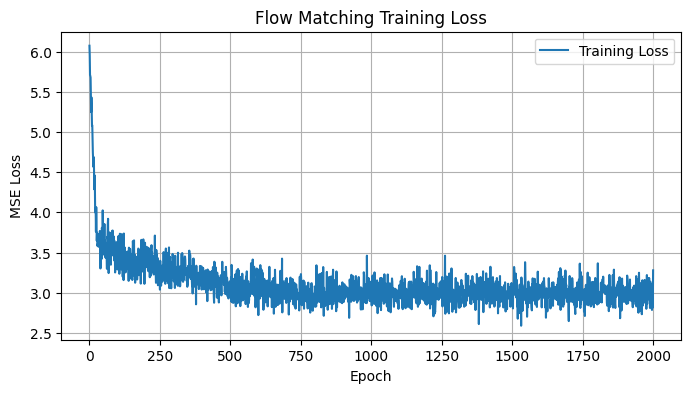

Initial Loss: 6.072749614715576
Final Loss: 3.2783844470977783


In [ ]:

# Step 6：绘制 Flow Matching Training Loss

import matplotlib.pyplot as plt

# 创建绘图窗口
# figsize=(8, 4)：宽度8英寸，高度4英寸
plt.figure(figsize=(8, 4))

# 绘制 Training Loss 曲线
# loss_history：Step 5 保存的每轮 Loss
# 横轴：Epoch
# 纵轴：MSE Loss
plt.plot(loss_history, label="Training Loss")

# 设置图表标题
plt.title("Flow Matching Training Loss")

# 设置横轴和纵轴名称
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

# 显示图例和网格
plt.legend()
plt.grid(True)

# 显示图表
plt.show()

# 输出初始 Loss 和最终 Loss
print("Initial Loss:", loss_history[0])
print("Final Loss:", loss_history[-1])


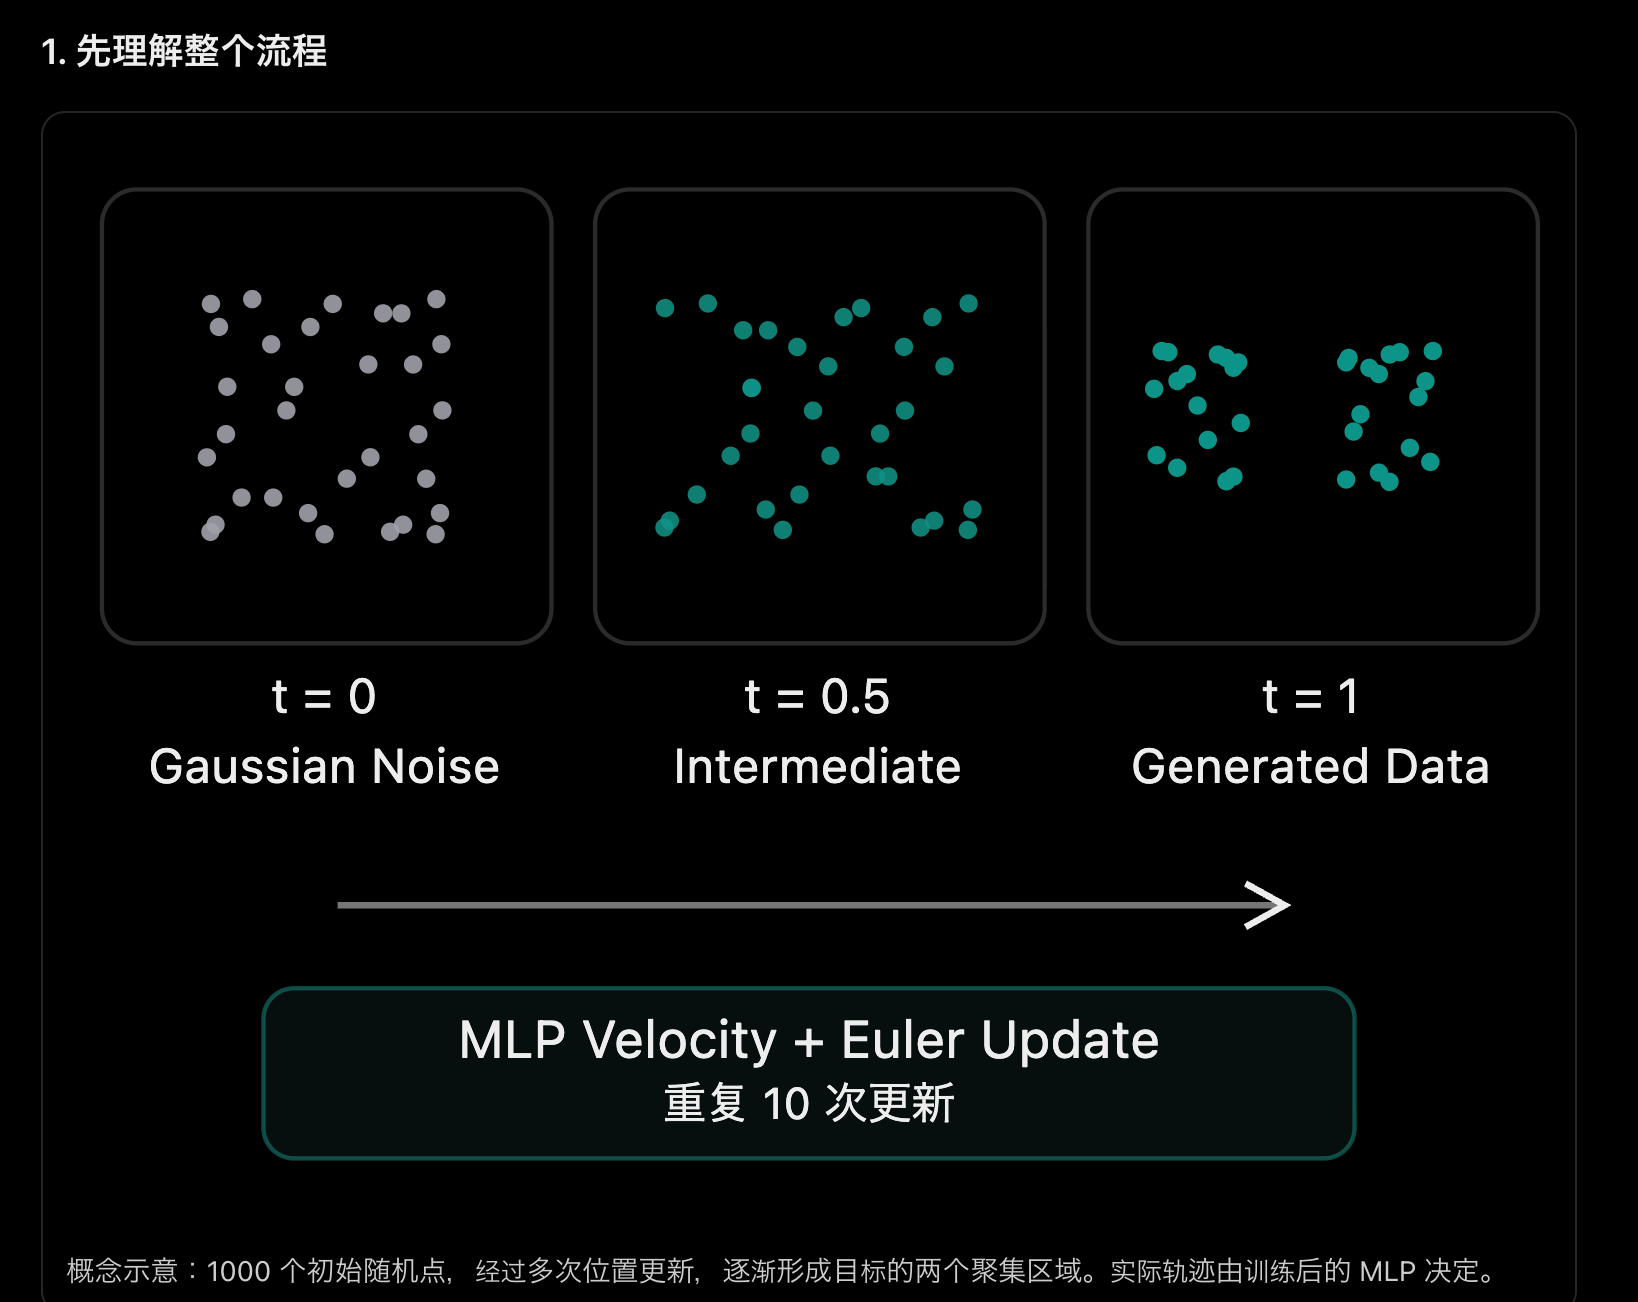

In [ ]:
# Euler Solver（欧拉求解器）：一种数值求解 ODE（Ordinary Differential Equation，常微分方程）的方法。
# #核心思想：根据当前位置和当前速度，计算下一时刻的位置。
# Euler Solver 就是把 ODE 的连续运动轨迹，近似成一段一段的直线来求解。

# 具体来说：
# 1. 在当前点 \(x_t\)，MLP 预测当前速度 \(v_\theta(x_t,t)\)。
# 2. 假设在很短的时间 \(\Delta t\) 内，速度保持不变，沿直线移动。
# 3. 到达新位置后，重新预测速度，再沿下一段直线移动。

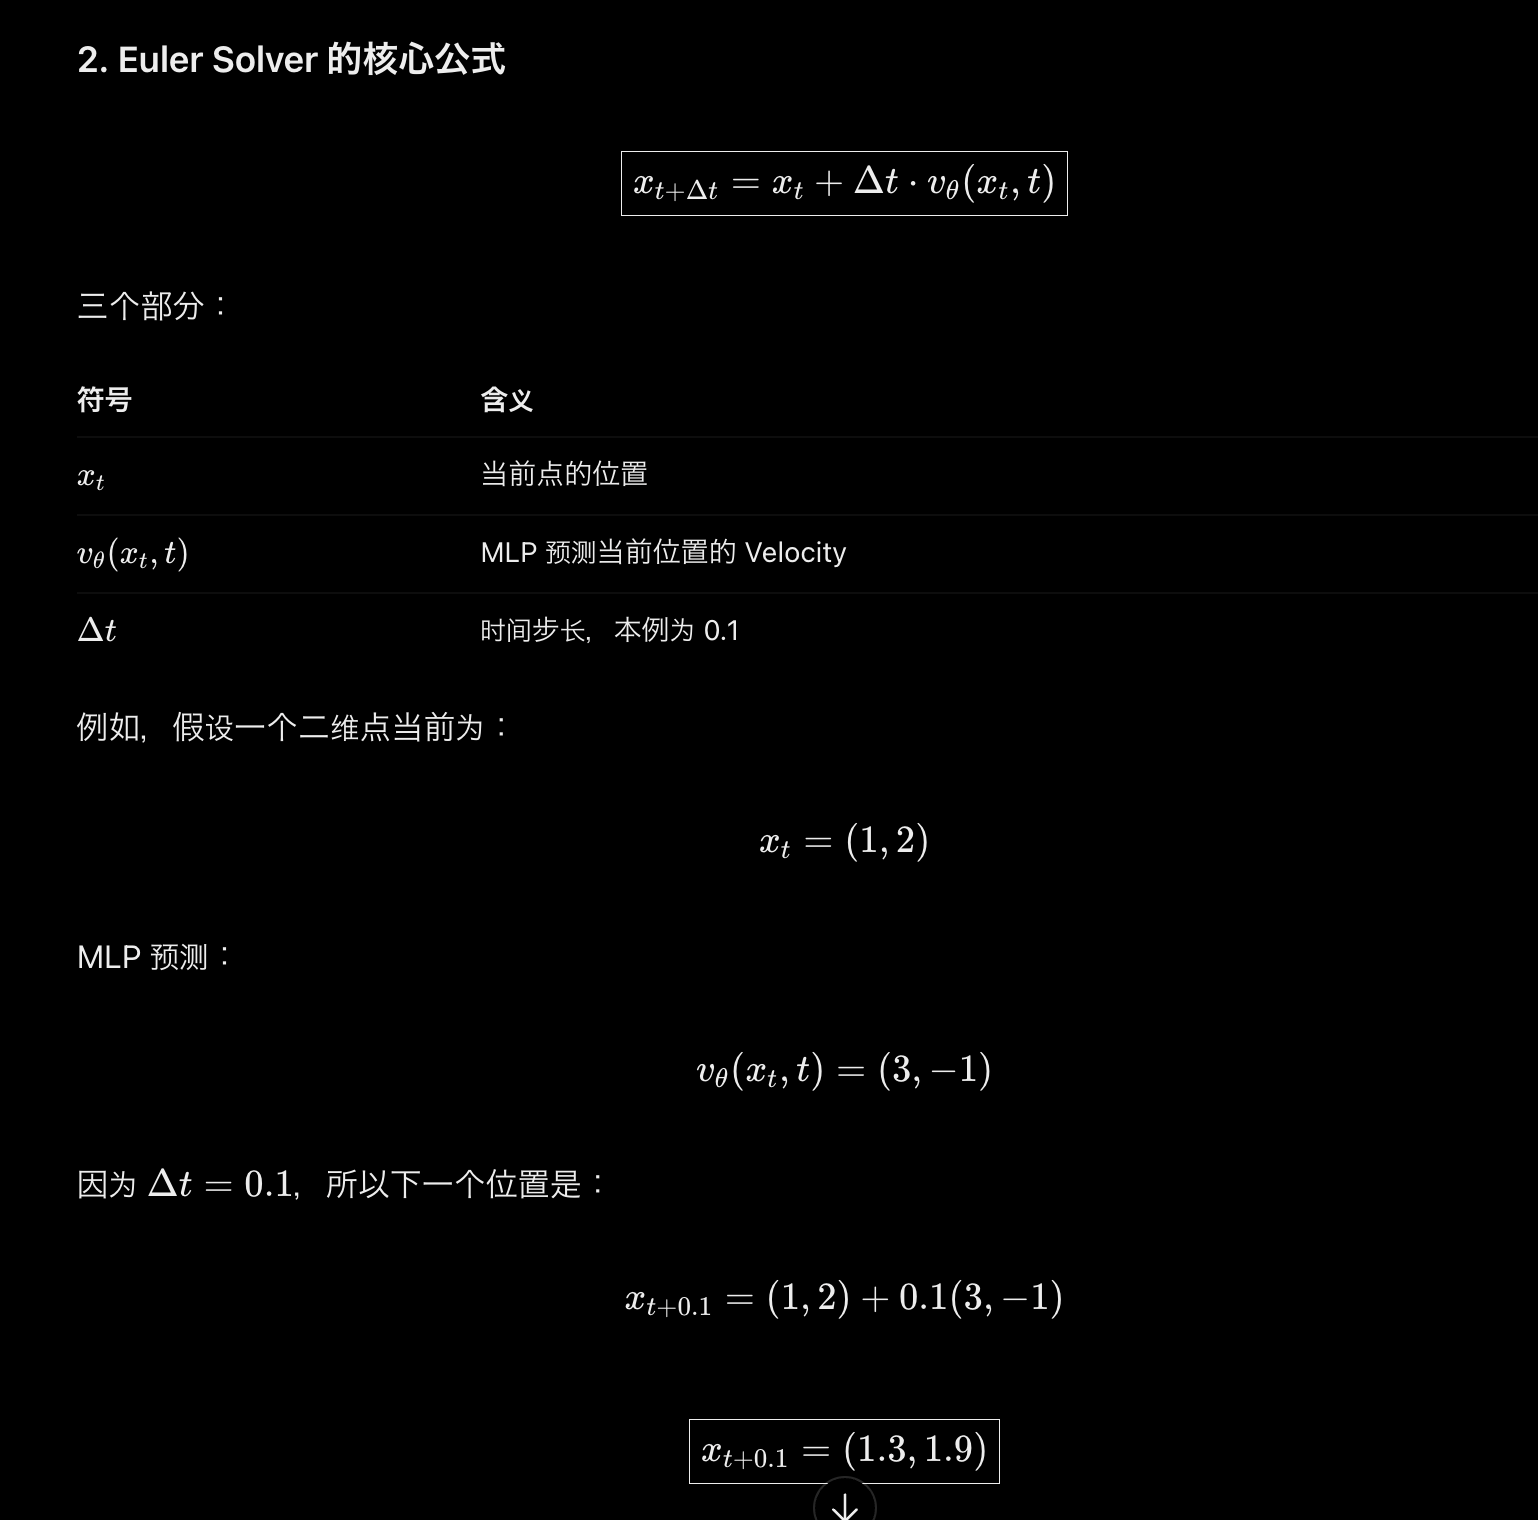

也就是：
- X 方向移动 +0.3
- Y 方向移动 -0.1
这就是一次 Euler Update。

In [ ]:
# 1. 基本语法
# torch.full(size, fill_value)
# - size：Tensor 的形状（Shape）
# - fill_value：填充的数值

# 例如：
# t = torch.full((3, 1), 0.5)print(t)

# 输出：
# tensor([[0.5],
#         [0.5],
#         [0.5]])

In [ ]:
# x.shape[0]	数据点数量，例如 1000 个
# (x.shape[0], 1)	输出 Shape = (1000, 1)
# t_span[step - 1]	获取当前 Euler Step 的时间
# .item()	将单元素 Tensor 转换为 Python 数值


In [ ]:
# Step 7：使用 Euler Solver 生成二维数据
# 定义 Euler Solver
# 这里的 estimator 就是之前训练好的 MLP 神经网络（Velocity Predictor）。
def solve_euler(x, t_span, estimator):

    # 保存每一步生成的数据，后续用于可视化
    sol = [x.clone()]

    # 关闭梯度计算：推理阶段不需要 Backpropagation
    with torch.no_grad():

        # 按照时间顺序逐步更新
        for step in range(1, len(t_span)):

            # 获取当前时间 t
            # Shape：(1000, 1)
            t = torch.full(
                (x.shape[0], 1),
                t_span[step - 1].item(),
                device=x.device
            )

            # 计算当前时间步长 Δt
            dt = t_span[step] - t_span[step - 1]

            # 使用训练好的 MLP 即estimator来预测 Velocity
            # 输入：当前位置 x + 当前时间 t
            # 输出：Predicted Velocity，Shape：(1000, 2)
            dphi_dt = estimator(x, t)

            # Euler Update：根据速度更新位置
            # x_next = x_current + Δt × Predicted Velocity
            x = x + dt * dphi_dt


            # x	当前 1000 个二维点的位置，Shape = (1000, 2)
            # x.clone()	复制当前 x，生成独立的 Tensor
            # sol.append()	将复制的 Tensor 添加到列表 sol 末尾

            # 保存更新后的点
            sol.append(x.clone())

    return x, sol

sol的含义
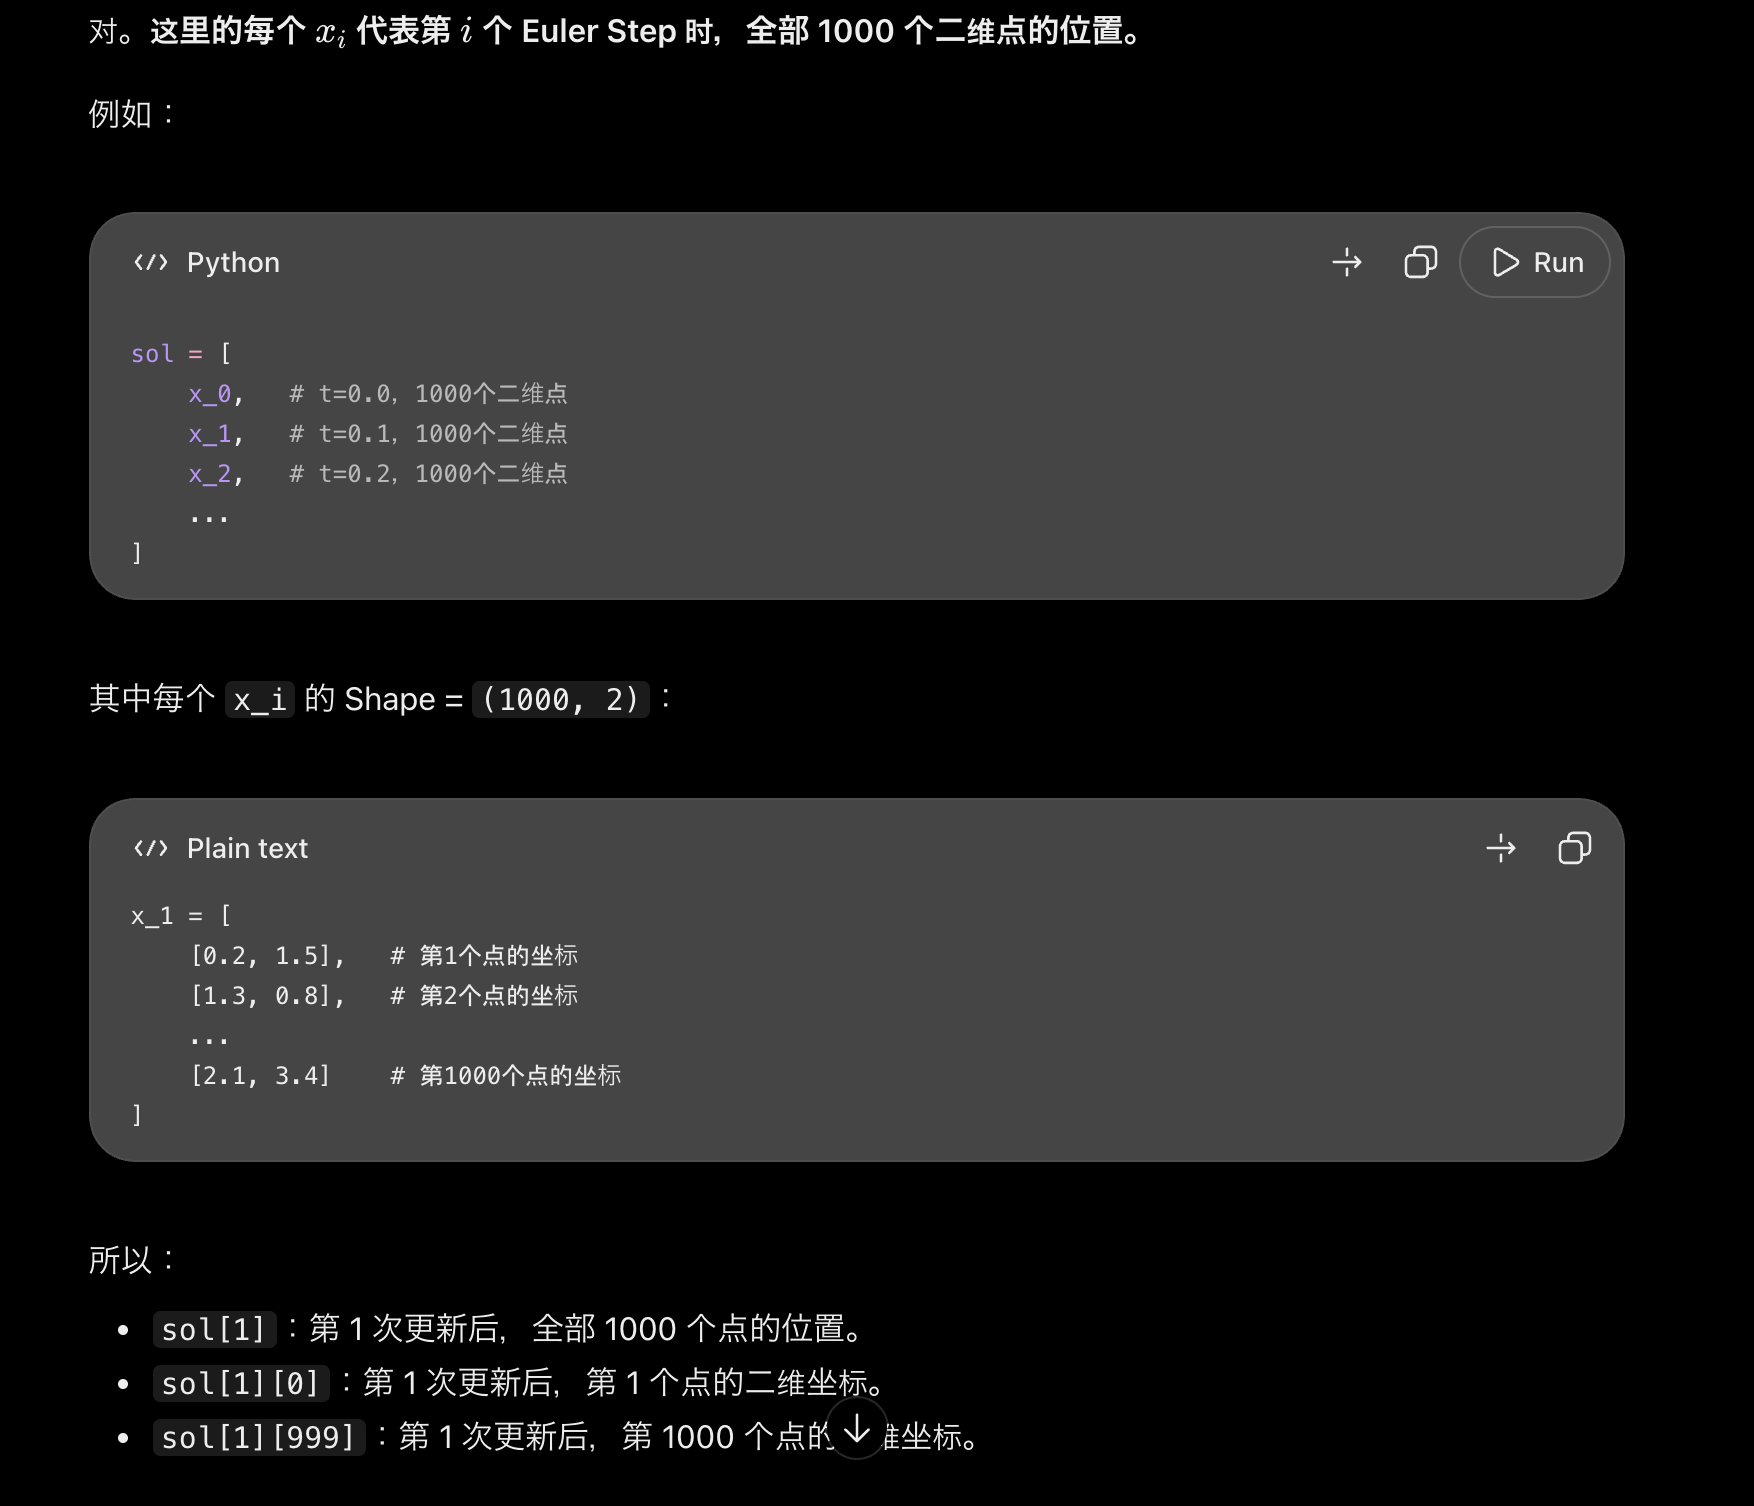

In [ ]:
# 创建1000个新的 Gaussian Noise 点
# Shape：(1000, 2)
z = torch.randn(1000, 2, device=device)

# 设置 Sampling Steps
# 10步意味着将时间0～1分成10段
n_timesteps = 10

# 创建时间序列：0, 0.1, 0.2, ..., 1.0
t_span = torch.linspace(0, 1, n_timesteps + 1, device=device)

# 设置模型为 Evaluation Mode
estimator.eval()

# 调用 Euler Solver
generated, sol = solve_euler(z, t_span, estimator)

# 查看结果
print("Initial Noise Shape:", z.shape)
print("Generated Data Shape:", generated.shape)
print("Saved Steps:", len(sol))


Initial Noise Shape: torch.Size([1000, 2])
Generated Data Shape: torch.Size([1000, 2])
Saved Steps: 11


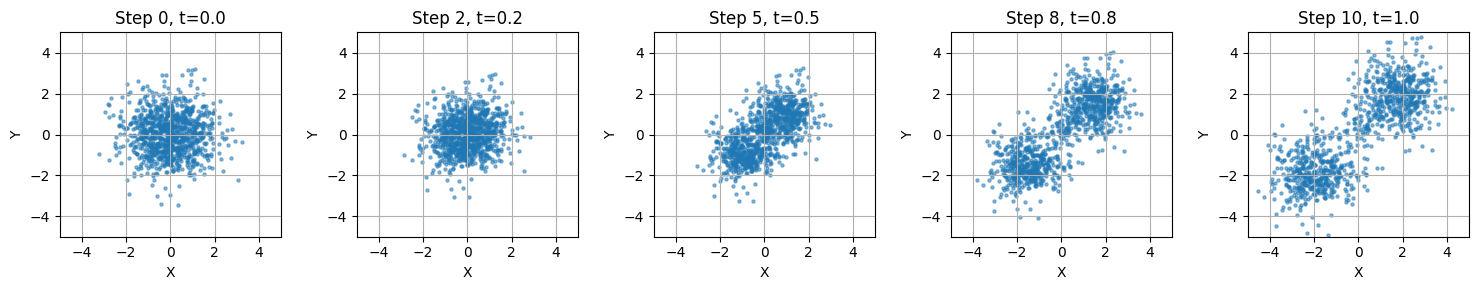

In [ ]:
# Step	预期变化
# 0	点主要集中在 (0, 0) 附近，呈 Gaussian Distribution
# 2	点开始沿学习到的 Velocity Field 移动
# 5	分布可能开始拉伸，并逐渐形成两个区域
# 8	两个聚集区域可能更加明显
# 10	最终形成接近目标数据的两个点群
# Step 8：可视化 Flow Matching 的生成过程

import matplotlib.pyplot as plt

# 选择需要观察的 Sampling Steps
# Step 0：初始 Gaussian Noise
# Step 2、5、8：中间生成过程
# Step 10：最终生成结果
steps_to_show = [0, 2, 5, 8, 10]

# 创建5个子图
# figsize=(15, 3)：宽15英寸，高3英寸
fig, axes = plt.subplots(1, 5, figsize=(15, 3))

# 依次绘制不同时间的数据分布
for ax, step in zip(axes, steps_to_show):

    # 从 sol 中读取指定 Step 的数据
    # detach()：与计算图分离
    # cpu()：移动到 CPU
    # numpy()：转换为 NumPy Array
    points = sol[step].detach().cpu().numpy()

    # 绘制二维散点图
    # [:, 0]：所有点的 X 坐标
    # [:, 1]：所有点的 Y 坐标
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.5)

    # 设置标题和坐标轴
    ax.set_title(f"Step {step}, t={step/10:.1f}")
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(True)

# 调整图像布局
plt.tight_layout()

# 显示生成过程
plt.show()


In [ ]:
这里的 estimator 就是你前面定义并训练的那个 MLP 神经网络